Arquivos gerados: CONSOLIDADO_FINAL_ALL_SCENARIOS.csv, RESUMO_MEDIA_CENARIOS.csv
Gráficos gerados: GRAFICO_ASR_COMPARATIVO.png, GRAFICO_F1_COMPARATIVO.png

Resumo Numérico (ASR):
Scenario           Majority (Baseline)  On-Off (Memory)  Scaling (Magnitude)  \
Strategy                                                                       
Adaptive_Ultimate             0.303057         0.259581             0.303057   
FLAME                         0.450332         0.251329             0.785470   
FLTrust                       0.354096         0.281049             0.356890   
FedAvg                        0.434400         0.320517             0.377872   
Krum                          0.456703         0.314115             0.322494   

Scenario           Sybil (Identity)  
Strategy                             
Adaptive_Ultimate          0.374175  
FLAME                      0.386266  
FLTrust                    0.373634  
FedAvg                     0.374091  
Krum                       0.479

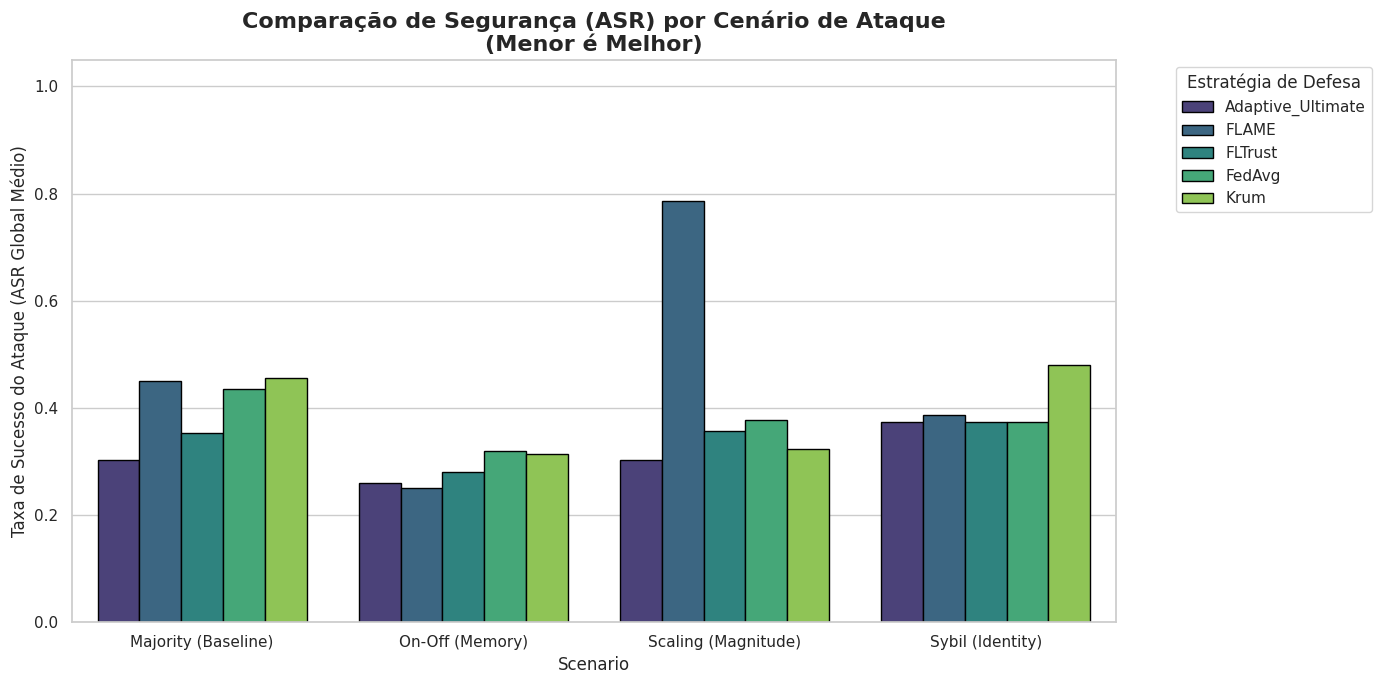

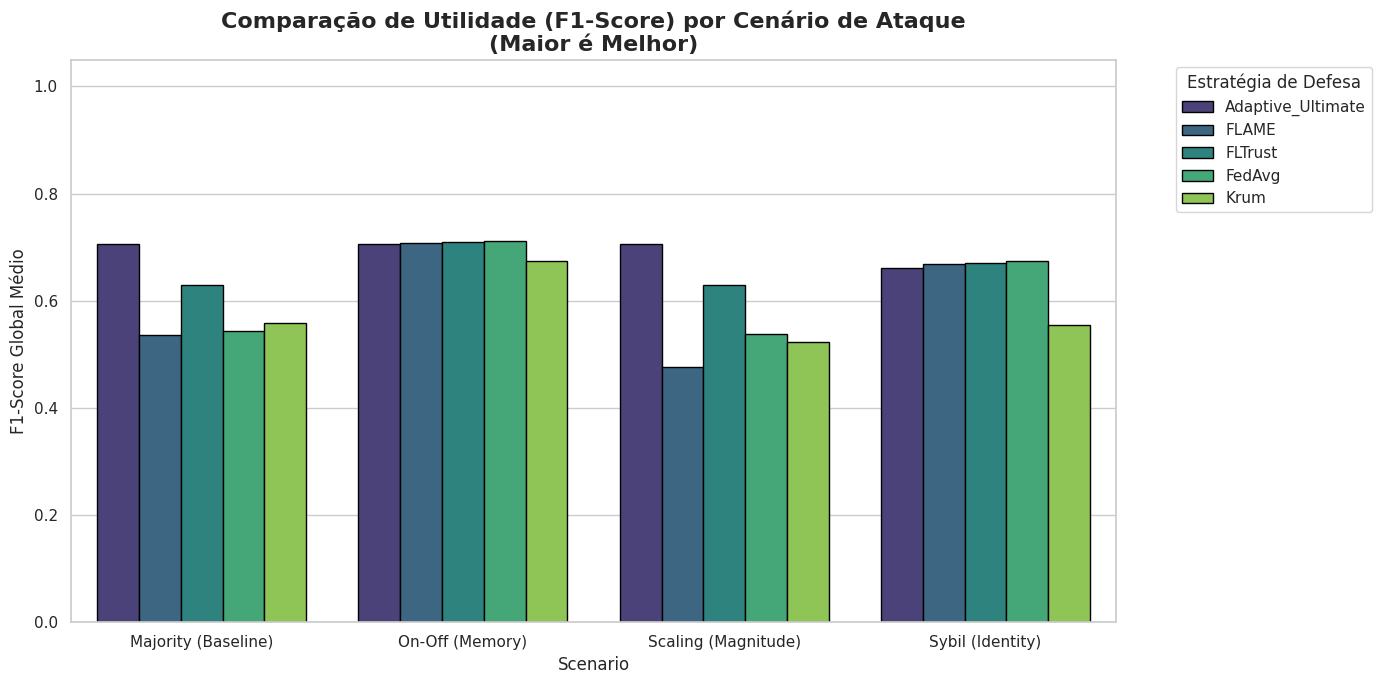

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load DataFrames
df_majority = pd.read_csv("RELATORIO_BACKDOOR_GERAL.csv")
df_onoff = pd.read_csv("RELATORIO_ONOFF_GERAL.csv")
df_scaling = pd.read_csv("RELATORIO_SCALING_GERAL.csv")
df_sybil = pd.read_csv("RELATORIO_SYBIL_GERAL.csv")

# Standardize Columns
# Majority has _Mean suffixes
df_majority = df_majority.rename(columns={'F1_Mean': 'F1', 'ASR_Mean': 'ASR'})
# Keep only necessary columns
cols = ['Strategy', 'F1', 'ASR', 'Dataset']

df_majority = df_majority[cols].copy()
df_onoff = df_onoff[cols].copy()
df_scaling = df_scaling[cols].copy()
df_sybil = df_sybil[cols].copy()

# Add Scenario Label
df_majority['Scenario'] = 'Majority (Baseline)'
df_onoff['Scenario'] = 'On-Off (Memory)'
df_scaling['Scenario'] = 'Scaling (Magnitude)'
df_sybil['Scenario'] = 'Sybil (Identity)'

# Concatenate
df_all = pd.concat([df_majority, df_onoff, df_scaling, df_sybil], ignore_index=True)

# Calculate Global Mean per Scenario/Strategy (averaging across all datasets)
summary = df_all.groupby(['Scenario', 'Strategy'])[['F1', 'ASR']].mean().reset_index()

# Save Consolidated CSV
df_all.to_csv("CONSOLIDADO_FINAL_ALL_SCENARIOS.csv", index=False)
summary.to_csv("RESUMO_MEDIA_CENARIOS.csv", index=False)

# --- PLOTTING ---
sns.set(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# 1. ASR Comparison
plt.figure(figsize=(14, 7))
sns.barplot(data=summary, x='Scenario', y='ASR', hue='Strategy', palette='viridis', edgecolor='black')
plt.title('Comparação de Segurança (ASR) por Cenário de Ataque\n(Menor é Melhor)', fontsize=16, fontweight='bold')
plt.ylabel('Taxa de Sucesso do Ataque (ASR Global Médio)')
plt.ylim(0, 1.05)
plt.legend(title='Estratégia de Defesa', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('GRAFICO_ASR_COMPARATIVO.png', dpi=300)

# 2. F1 Comparison
plt.figure(figsize=(14, 7))
sns.barplot(data=summary, x='Scenario', y='F1', hue='Strategy', palette='viridis', edgecolor='black')
plt.title('Comparação de Utilidade (F1-Score) por Cenário de Ataque\n(Maior é Melhor)', fontsize=16, fontweight='bold')
plt.ylabel('F1-Score Global Médio')
plt.ylim(0, 1.05)
plt.legend(title='Estratégia de Defesa', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('GRAFICO_F1_COMPARATIVO.png', dpi=300)

print("Arquivos gerados: CONSOLIDADO_FINAL_ALL_SCENARIOS.csv, RESUMO_MEDIA_CENARIOS.csv")
print("Gráficos gerados: GRAFICO_ASR_COMPARATIVO.png, GRAFICO_F1_COMPARATIVO.png")
print("\nResumo Numérico (ASR):")
print(summary.pivot(index='Strategy', columns='Scenario', values='ASR'))